# Fase 4 · Proyecto integrador TMDB (2010–2025) — Grupo 4
## Del problema original a la evaluación final: decisiones, evidencias y límites

**Propósito.** Reconstruir el camino seguido por el Grupo 4 desde la definición de la pregunta (F1), la preparación del catálogo (F2) y la construcción del núcleo algorítmico (F3), hasta una evaluación explicativa y reproducible (F4). No se trata de acumular gráficos: cada figura debe responder una pregunta y motivar la siguiente decisión.

**Regla de procedencia.** El repositorio público [`yetgx/mcdi500-tmdb-grupo4`](https://github.com/yetgx/mcdi500-tmdb-grupo4), rama `main`, es la referencia del proyecto. Este cuaderno se ejecuta dentro de un clon; su commit se registra para distinguir una medición reproducible de una versión simplemente descrita. La retroalimentación docente solicita expresamente **reutilizar los artefactos finales de F3**, analizar 3.596 consultas, justificar los pesos 0,5/0,5, construir intervalos bootstrap por consulta, estudiar sesgos por idioma, diversidad y casos concretos.

**Criterio académico.** Cuando no hay un archivo que demuestre una cifra o decisión, el notebook la identifica como *no verificada*, sin sustituirla por una cifra inventada. Las conclusiones cuantitativas se generan de las salidas efectivamente obtenidas.

## El recorrido completo: una decisión condujo a la siguiente

La trayectoria del Grupo 4 no puede explicarse como cuatro entregas independientes. La definición de *qué* recomendar determinó *qué* información conservar; las dificultades de representación condicionaron *cómo* calcular similitudes; la necesidad de mantener un procesamiento comprobable llevó a modularizarlo; y las métricas inicialmente planteadas determinaron *qué* visualizar al cierre.

| Momento | Pregunta que surgió | Respuesta técnica verificable | Consecuencia para la fase siguiente |
|---|---|---|---|
| **F1 · Planteamiento** | ¿Qué significa una recomendación coherente? | Tres indicadores: género, idioma y votos, comparables con azar | Define las variables y relaciones que F2 debe preservar |
| **F2 · Preparación** | ¿Cómo convertir metadatos heterogéneos en datos procesables sin perder la identidad de cada película? | Limpieza, `movie_id`, `metadata_soup`, CSV procesado y Bag of Words disperso | Hace posibles comparaciones vectoriales y atributos interpretables |
| **F3 · Ingeniería** | ¿Cómo reducir el acoplamiento y verificar costo temporal y espacial? | Módulos, transformadores, pruebas y benchmark | Permite auditar el camino algorítmico antes de interpretar resultados |
| **F4 · Síntesis** | ¿Qué evidencia existe a favor del enfoque y cuáles son sus límites? | Control aleatorio, resultados por indicador, gráficos y discusión | Permite responder la pregunta inicial sin confundir asociación con satisfacción |



## Capítulo 1 · Fase 1: de la necesidad de recomendar a una pregunta que puede ponerse a prueba

El proyecto surgió de una dificultad habitual en catálogos extensos: que dos películas resulten «parecidas» no constituye por sí mismo una definición operativa. Para construir una solución defendible, el Grupo 4 necesitaba acordar qué características de una sugerencia podían medirse y cómo distinguir una recomendación informada de una selección fortuita.

**Primera decisión documentada.** El planteamiento publicado por el equipo considera similitud de contenido —incluidos géneros, productoras e idioma— combinada con señales de calidad y popularidad. Para evaluar resultados se establecieron **tres propiedades observables** de un conjunto top-10: compartir al menos un género, coincidir en idioma original y alcanzar un volumen de votos situado por encima del percentil 75 del catálogo. Una línea base aleatoria ofrece contexto para las proporciones observadas.

**Por qué esta decisión fue necesaria.** La afinidad temática, la consistencia lingüística y el respaldo de votos representan dimensiones diferentes. Un modelo podría proponer títulos del mismo género y, aun así, recomendar obras poco conocidas; o priorizar títulos muy votados pero alejados de la consulta. Separar indicadores permite detectar esos compromisos, en lugar de esconderlos en una puntuación única.

**Qué se obtiene en esta fase.** Se establece un criterio de éxito comprobable; todavía **no** se demuestra que los usuarios prefieran las recomendaciones. Los votos miden participación y el género o el idioma son aproximaciones basadas en metadatos. Esta distinción determina cómo interpretaremos los resultados al final del recorrido.

**Transición hacia F2.** Una vez definido lo que queríamos comparar, fue necesario preparar los metadatos sin perder la correspondencia entre cada película y sus atributos originales.

In [1]:
from pathlib import Path
import os
import sys
import platform
import subprocess
import json
import inspect
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

# ============================================================
# 1. CONFIGURACIÓN DE REPRODUCIBILIDAD
# ============================================================

SEMILLA = 42
rng = np.random.default_rng(SEMILLA)

# ============================================================
# 2. IDENTIFICACIÓN DE LA RAÍZ DEL REPOSITORIO
# ============================================================

RAIZ = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "README.md").exists()
        and (p / "F1").is_dir()
        and (p / "F2").is_dir()
        and (p / "F3").is_dir()
    ),
    None
)

if RAIZ is None:
    raise FileNotFoundError(
        "No se encontró la raíz del proyecto. "
        "Abra el notebook dentro del repositorio "
        "mcdi500-tmdb-grupo4."
    )

# ============================================================
# 3. FUNCIÓN PARA CONSULTAR INFORMACIÓN DE GIT
# ============================================================

def git(*args):
    """Ejecuta una consulta Git desde la raíz del proyecto."""
    return subprocess.check_output(
        ["git", "-C", str(RAIZ), *args],
        text=True,
        encoding="utf-8",
        errors="replace"
    ).strip()

# ============================================================
# 4. IDENTIFICACIÓN DE RAMA Y COMMITS
# ============================================================

try:
    rama = git("branch", "--show-current")
    head = git("rev-parse", "HEAD")
except (subprocess.CalledProcessError, FileNotFoundError) as e:
    raise RuntimeError(
        "No fue posible consultar Git. "
        "Verifique que el proyecto sea un repositorio válido."
    ) from e

try:
    remoto = git("rev-parse", "--verify", "refs/remotes/origin/main")
except (subprocess.CalledProcessError, FileNotFoundError):
    remoto = None

# ============================================================
# 5. IDENTIFICACIÓN TÉCNICA DEL PROYECTO COLECTIVO
# ============================================================
print("=" * 65)
print("MCDI500 | PROYECTO INTEGRADOR TMDB | GRUPO 4")
print("Fase 4: análisis y comunicación de resultados")
print("=" * 65)
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| NumPy:", np.__version__)
print("Entorno virtual activo:", sys.prefix != sys.base_prefix)
print("Semilla de reproducibilidad:", SEMILLA)

# La identidad del commit se conserva para auditoría del trabajo grupal.
# No se muestra el nombre de la rama personal como hallazgo científico.
print("\n=== REGISTRO DE TRAZABILIDAD COLECTIVA ===")
print("Repositorio público: yetgx/mcdi500-tmdb-grupo4")
print("Versión de código ejecutada (commit):", head[:12])
if remoto and remoto == head:
    print("El commit coincide con la referencia local origin/main.")
else:
    print("AVISO: no está demostrada la coincidencia con el último main remoto.")
    print("La referencia origin/main es local y puede requerir actualización.")
print("La información de rama puede auditarse con Git sin integrarla al relato de hallazgos.")

# ============================================================
# 7. VERIFICACIÓN DE ARCHIVOS DE ENTRADA
# ============================================================

print("\n=== VERIFICACIÓN DE DATOS ===")

RUTA_RAW = RAIZ / "data" / "raw" / "movies_raw.csv"

if not RUTA_RAW.is_file():
    raise FileNotFoundError(
        f"No se encontró el dataset original:\n{RUTA_RAW}"
    )

if RUTA_RAW.stat().st_size == 0:
    raise ValueError(
        "El archivo movies_raw.csv existe, pero está vacío."
    )

print(f"Dataset localizado: {RUTA_RAW.relative_to(RAIZ).as_posix()}")
print(f"Tamaño del archivo: {RUTA_RAW.stat().st_size:,} bytes")

print("\nVerificación inicial del entorno: COMPLETADA.")
print("El contenido del dataset se validará en la siguiente etapa.")

MCDI500 | PROYECTO INTEGRADOR TMDB | GRUPO 4
Fase 4: análisis y comunicación de resultados
Python: 3.13.17
pandas: 3.1.1 | NumPy: 2.5.4
Entorno virtual activo: True
Semilla de reproducibilidad: 42

=== REGISTRO DE TRAZABILIDAD COLECTIVA ===
Repositorio público: yetgx/mcdi500-tmdb-grupo4
Versión de código ejecutada (commit): a19591bb939d
AVISO: no está demostrada la coincidencia con el último main remoto.
La referencia origin/main es local y puede requerir actualización.
La información de rama puede auditarse con Git sin integrarla al relato de hallazgos.

=== VERIFICACIÓN DE DATOS ===
Dataset localizado: c:\Users\JP\Desktop\mcdi500-tmdb-grupo4\data\raw\movies_raw.csv
Tamaño del archivo: 3,363,326 bytes

Verificación inicial del entorno: COMPLETADA.
El contenido del dataset se validará en la siguiente etapa.


### Primera decisión transversal: documentar condiciones reproducibles, sin personalizar la historia

Una investigación desarrollada por varias personas necesita que el código y sus resultados sean identificables. Por eso el proyecto se apoya en control de versiones, dependencias explícitas y una semilla de aleatoriedad. La primera celda registra las versiones de Python, pandas y NumPy, detecta el entorno virtual, localiza el repositorio y comprueba que el archivo original exista y no esté vacío.

**Lectura de la evidencia.** Esta comprobación establece las condiciones técnicas mínimas para interpretar las operaciones posteriores; **no certifica** que la recomendación sea buena ni, por sí sola, que todos los resultados sean reproducibles. Un commit identifica una versión de código; además se requiere verificar sus entradas y ejecutar todas las celdas sin errores.

**Decisión del Grupo 4.** La trazabilidad se mantiene como información técnica auditable, mientras que el texto académico se concentra en la evolución colectiva. No se presentan ramas personales ni identidades de trabajo en los hallazgos, porque no explican por qué se limpiaron los datos, se eligió una representación o se compararon los algoritmos.

**Consecuencia.** Con las condiciones de ejecución identificadas, podemos estudiar los datos y comprobar si la información de partida es adecuada para los tres criterios que definió F1.

In [2]:
criterios = pd.DataFrame([
  {'objetivo':'Género compartido','referencia_readme':0.418,'interpretación':'≥1 género en común'},
  {'objetivo':'Idioma coincidente','referencia_readme':0.366,'interpretación':'mismo idioma original'},
  {'objetivo':'Votos sobre P75','referencia_readme':0.250,'interpretación':'vote_count ≥ P75 catálogo'},
])
display(criterios.assign(referencia_pct=lambda d:(100*d.referencia_readme).round(1)))
print('Estos son valores de referencia de F1; todavía no son resultados de F4.')

,objetivo,referencia_readme,interpretación,referencia_pct
0,Género compartido,0.418,≥1 género en común,41.8
1,Idioma coincidente,0.366,mismo idioma original,36.6
2,Votos sobre P75,0.250,vote_count ≥ P75 catálogo,25.0


Estos son valores de referencia de F1; todavía no son resultados de F4.


### Qué enseñan las referencias de F1 y cómo condicionaron la investigación

La tabla anterior traduce el planteamiento inicial del equipo a tres indicadores comparables. Las tasas de **41,8 %** (género), **36,6 %** (idioma) y **25,0 %** (votos) figuran en el README como **referencias de partida**: no son resultados obtenidos por el protocolo experimental ejecutado aquí.

Su valor metodológico es concreto. Antes de construir o evaluar recomendaciones, el Grupo 4 dejó establecida una comparación que permite distinguir resultados atribuibles al método de coincidencias plausibles por azar. Además, cada indicador determina qué atributos debe conservar F2 y qué figura deberá comunicar F4. **La decisión siguiente, por tanto, no era dibujar un gráfico: era preparar un catálogo en el que estas tres preguntas pudieran responderse sin ambigüedad.**

## Capítulo 2 · Fase 2: comprender el catálogo antes de transformarlo

El punto de partida fue un conjunto de películas con variables de diferente naturaleza: identificadores, títulos, géneros, lenguas, votos, popularidad y metadatos textuales. Trabajar directamente sobre esas columnas habría dificultado tanto la comparación automática como la validación del tratamiento de valores faltantes. El desafío consistió en **limpiar y transformar sin destruir la identidad ni la interpretación de cada película**.

**Decisión observable del equipo.** En F2 se generó un conjunto procesado, se conservaron claves `movie_id` y se construyeron atributos que posteriormente alimentan la similitud y las puntuaciones de recomendación. El archivo original permanece sin modificación. Esta separación permite contrastar el punto de partida con el resultado de preparación y detectar pérdidas de registros o desalineaciones.

**Justificación.** Un recomendador necesita identificar inequívocamente cada película para excluir la consulta de sus propias sugerencias y unir las representaciones vectoriales con información legible. Si la limpieza altera el orden o elimina filas sin conservar correspondencias, una similitud numéricamente correcta puede terminar asociada al título equivocado.

**Evidencia a observar en la siguiente celda.** La comparación entre tamaños, cantidad y unicidad de identificadores y patrones de faltantes permite comprobar qué se conservó y qué variables requirieron atención. No interpretaremos la ausencia de cambios en el número de filas como prueba de que toda imputación fue acertada; solo demuestra que no se perdieron identificadores.

In [3]:
raw_path = RAIZ/'data/raw/movies_raw.csv'
proc_path = RAIZ/'data/processed/movies_procesado.csv'
assert proc_path.exists(), 'Falta el CSV procesado de F2 en main.'
raw = pd.read_csv(raw_path,low_memory=False)
proc = pd.read_csv(proc_path,low_memory=False)
assert 'movie_id' in raw and 'movie_id' in proc
assert raw.movie_id.is_unique and proc.movie_id.is_unique
assert raw.movie_id.notna().all() and proc.movie_id.notna().all()
assert set(raw.movie_id)==set(proc.movie_id), 'Los ID de F2 no coinciden con F1.'
print('F1 original:',raw.shape, '| F2 procesado:',proc.shape)
print('Identificadores únicos en F1/F2:',raw.movie_id.nunique(),proc.movie_id.nunique())
print('Orden de ID idéntico:',raw.movie_id.tolist()==proc.movie_id.tolist())
print('Columnas F2:',proc.columns.tolist())
print('Faltantes principales de origen:')
display(raw.isna().sum().sort_values(ascending=False).head(8).rename('faltantes').to_frame())
print('Tipos de los atributos numéricos clave:')
display(proc[[x for x in ['vote_average','vote_count','popularity','weighted_rating','score_quality_norm','score_popularity_norm'] if x in proc]].dtypes.rename('dtype').to_frame())

F1 original: (17978, 16) | F2 procesado: (17978, 16)
Identificadores únicos en F1/F2: 17978 17978
Orden de ID idéntico: True
Columnas F2: ['movie_id', 'title', 'release_date', 'genres_clean', 'companies_clean', 'lang_clean', 'metadata_soup', 'vote_average', 'vote_count', 'popularity', 'weighted_rating', 'score_quality_norm', 'score_popularity_norm', 'runtime_clean', 'budget_clean', 'revenue_clean']
Faltantes principales de origen:


,faltantes
production_companies,494
production_countries,176
spoken_languages,92
genres,10
status,0
movie_id,0
release_date,0
title,0


Tipos de los atributos numéricos clave:


,dtype
vote_average,float64
vote_count,int64
popularity,float64
weighted_rating,float64
score_quality_norm,float64
score_popularity_norm,float64


### Primer hallazgo de preparación: conservar películas no significa conservar los datos intactos

La lectura del CSV original y del procesado permite comprobar si se mantiene el universo de películas. En la ejecución aportada, **ambos conservaron 17.978 registros**, y las comprobaciones de identificadores confirmaron la correspondencia requerida para continuar el análisis. Este resultado es importante porque el sistema necesita relacionar las características originales con las nuevas variables que alimentan los algoritmos.

**Interpretación que justifica la decisión.** La preparación no consistió simplemente en «quitar filas malas»: el equipo optó por conservar la cobertura del catálogo y transformar su representación. La tabla de faltantes muestra dónde estaban las principales ausencias antes del tratamiento; los tipos de las nuevas columnas permiten comprobar qué atributos ya pueden procesarse matemáticamente. Estas observaciones explican por qué fue necesario un paso sistemático de transformación antes de construir recomendaciones.

**Consecuencia para el camino recorrido.** A partir de un catálogo con atributos heterogéneos se obtiene una estructura comparable, pero aún falta traducir metadatos textuales en una forma sobre la que pueda calcularse similitud. Esa necesidad explica la construcción de `metadata_soup` y Bag of Words.

**Límite.** La igualdad de IDs y filas no certifica por sí sola la pertinencia semántica de cada transformación; esa cuestión requiere inspección de funciones y pruebas específicas de F2.

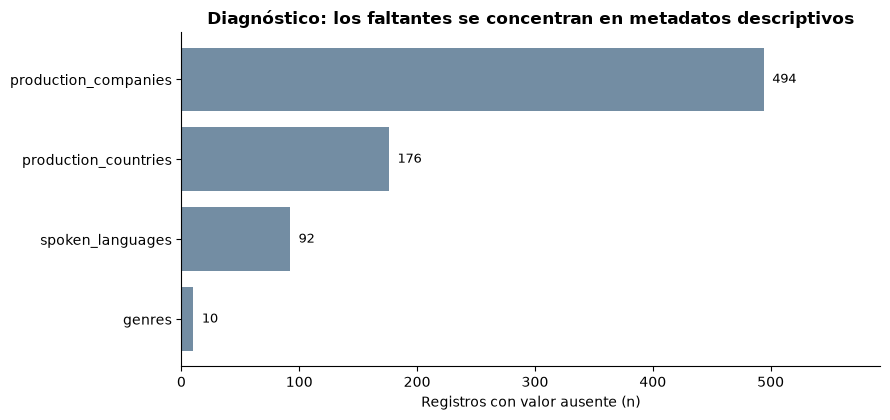

**Interpretación y consecuencia.** Se identificaron **4 campos con faltantes**; el más afectado fue **production_companies**, con **494** registros. Esta evidencia justifica una limpieza diferenciada y explica por qué las categorías deben normalizarse antes de construir la representación de similitud. **Límite:** una frecuencia de nulos no informa por sí sola la causa de ausencia ni permite inferir preferencias de los usuarios.

In [4]:
# Figura de diagnóstico. Los datos son los faltantes reales del CSV original.
faltantes = raw.isna().sum().sort_values(ascending=False)
con_faltantes = faltantes[faltantes.gt(0)].head(10).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.barh(con_faltantes.index, con_faltantes.to_numpy(), color='#738DA3')
for y, n in enumerate(con_faltantes.to_numpy()):
    ax.text(n + max(2,con_faltantes.max()*.015), y, str(int(n)), va='center', fontsize=9)
ax.set_xlim(0, max(con_faltantes.max()*1.2, 1))
ax.set_xlabel('Registros con valor ausente (n)')
ax.set_title('Diagnóstico: los faltantes se concentran en metadatos descriptivos', weight='bold')
ax.spines[['right','top']].set_visible(False)
fig.tight_layout(); plt.show()
principal = faltantes[faltantes.gt(0)]
display(Markdown(f"**Interpretación y consecuencia.** Se identificaron **{len(principal)} campos con faltantes**; "
                 f"el más afectado fue **{principal.index[0]}**, con **{int(principal.iloc[0]):,}** registros. "
                 "Esta evidencia justifica una limpieza diferenciada y explica por qué las categorías deben "
                 "normalizarse antes de construir la representación de similitud. **Límite:** una frecuencia de nulos "
                 "no informa por sí sola la causa de ausencia ni permite inferir preferencias de los usuarios."))

### Una decisión distinta: datos para calcular no son datos para explicar

El dataset procesado facilita los cálculos, pero la interpretación de un informe necesita categorías legibles y valores con unidades originales. Por eso F4 utilizará una **tabla de visualización** recuperando géneros, idioma y votos originales y uniéndolos por `movie_id` con las filas procesadas. No “deshace” automáticamente todas las transformaciones ni presume que el valor normalizado sea un número de votos: **reconstruye una vista interpretable de forma controlada**.

## Capítulo 3 · F2: convertir atributos de películas en una representación comparable

Al completar la limpieza apareció una dificultad distinta. Géneros, productoras, idiomas y términos descriptivos son útiles para explicar una película, pero no pueden compararse directamente con operaciones vectoriales sin una codificación. El proyecto necesitaba **una representación común del contenido**.

**Decisión implementada.** F2 reunió atributos textuales en `metadata_soup` y generó una matriz Bag of Words (BOW). Cada fila corresponde a una película y cada columna a un término del vocabulario. Para no almacenar posiciones que valen cero, se conservó una representación **dispersa**. El código siguiente carga ese artefacto si existe y verifica que sus filas sigan correspondiendo a las películas del CSV procesado.

**Justificación y alternativa evitada.** Una matriz densa de todas las parejas de películas es innecesaria para responder consultas individuales; el producto del vector de la consulta por la matriz de términos permite recuperar puntuaciones sin reservar toda una matriz de similitud N×N. Esto condiciona la viabilidad de la etapa experimental de F4.

**Prueba relevante.** Las dimensiones, el número de elementos no nulos, la densidad y la memoria de la estructura CSR no son estadísticas decorativas: explican si la codificación aporta una base razonable para la comparación de contenido. Hay que distinguir esta representación de un aprendizaje semántico avanzado; BOW captura presencia o frecuencia de tokens, no comprensión del significado.

In [5]:
from scipy import sparse
from sklearn.preprocessing import normalize
from sklearn.feature_extraction.text import CountVectorizer
ruta_bow = RAIZ/'data/processed/movies_bow_matrix.npz'
if not ruta_bow.is_file():
    raise FileNotFoundError(
        f"Falta el artefacto F2 {ruta_bow}. F4 no reconstruye BOW: "
        "incorpore a main el artefacto preparado y verificable de F2."
    )
bow = sparse.load_npz(ruta_bow).tocsr()
origen_bow = str(ruta_bow.relative_to(RAIZ))
assert bow.shape[0]==len(proc), 'Filas BOW y CSV procesado no coinciden.'
bow = normalize(bow,norm='l2',axis=1).tocsr()
print('Representación:',origen_bow)
print('Forma matriz:',bow.shape,'| Entradas no nulas:',bow.nnz)
print('Densidad porcentual:',round(bow.nnz/(bow.shape[0]*bow.shape[1])*100,5))
print('Memoria estructuras CSR (MiB):',round((bow.data.nbytes+bow.indices.nbytes+bow.indptr.nbytes)/2**20,2))

Representación: data\processed\movies_bow_matrix.npz
Forma matriz: (17978, 13766) | Entradas no nulas: 102902
Densidad porcentual: 0.04158
Memoria estructuras CSR (MiB): 1.25


### Segundo hallazgo: la dispersidad hizo viable la comparación por contenido

La ejecución proporcionada registró una BOW de **17.978 películas por 13.766 atributos**, con una **densidad aproximada de 0,04158 %**. Es decir, casi todas las combinaciones entre película y término están vacías. Esta característica no representa un defecto del conjunto: refleja que cada película utiliza solo una pequeña parte del vocabulario global.

**Interpretación y decisión técnica.** Mantener la BOW en formato disperso evita representar explícitamente millones de posiciones cero. Por esa razón, el protocolo F4 calcula similitudes **consulta a catálogo**, en vez de construir de manera anticipada una matriz completa de similitudes entre todas las películas. Es una consecuencia concreta del diagnóstico de F2.

**Qué aporta al relato.** La información textual quedó convertida en una estructura numérica utilizable sin abandonar la correspondencia con `movie_id`. Este puente explica por qué F2 no termina con la limpieza: prepara el insumo sobre el que actúan los algoritmos y permite comprender el problema de eficiencia que aborda F3.

**Límite de la medición.** La densidad mide almacenamiento de términos, no calidad de las recomendaciones. Sus dimensiones deben verificarse nuevamente al ejecutar la versión definitiva de los artefactos de GitHub.

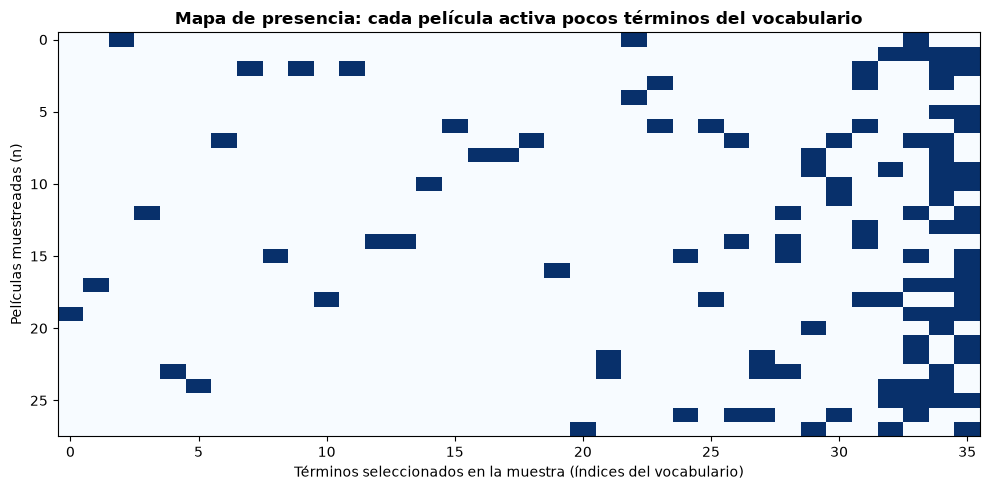

**Lectura de la figura.** En esta vista **deliberadamente seleccionada** de 28 películas y 36 términos, el **10.5 %** de las celdas es distinto de cero. No representa la densidad global: las columnas se eligieron por presencia en la muestra. La densidad global válida para el argumento de almacenamiento es la calculada en la celda anterior.

In [6]:
# Mapa de presencia de términos en una muestra reproducible: no crea una matriz densa global.
filas_muestra = np.random.default_rng(SEMILLA).choice(bow.shape[0], size=min(28,bow.shape[0]), replace=False)
frecuencia = np.asarray(bow[filas_muestra].getnnz(axis=0)).ravel()
columnas_muestra = np.argsort(frecuencia)[-min(36, np.count_nonzero(frecuencia)):]
submatriz = (bow[filas_muestra][:, columnas_muestra].toarray() > 0).astype(int)
fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(submatriz, aspect='auto', cmap='Blues', interpolation='nearest', vmin=0, vmax=1)
ax.set_xlabel('Términos seleccionados en la muestra (índices del vocabulario)')
ax.set_ylabel('Películas muestreadas (n)')
ax.set_title('Mapa de presencia: cada película activa pocos términos del vocabulario', weight='bold')
fig.tight_layout(); plt.show()
porcentaje_local = 100*submatriz.mean()
display(Markdown(f"**Lectura de la figura.** En esta vista **deliberadamente seleccionada** de "
                 f"{submatriz.shape[0]} películas y {submatriz.shape[1]} términos, "
                 f"el **{porcentaje_local:.1f} %** de las celdas es distinto de cero. "
                 "No representa la densidad global: las columnas se eligieron por presencia en la muestra. "
                 "La densidad global válida para el argumento de almacenamiento es la calculada en la celda anterior."))

## Capítulo 4 · Fase 3: pasar de un procesamiento funcional a un núcleo algorítmico defendible

La etapa siguiente no consistió simplemente en ejecutar transformaciones sobre un DataFrame. Una vez que el proyecto creció, se hizo necesario separar responsabilidades, reutilizar componentes y demostrar que el costo de procesamiento se conocía. El reto pasó de **obtener un resultado** a **obtenerlo de una manera comprobable y mantenible**.

**Decisiones observables.** En `src/` el proyecto organiza tareas de carga, preparación, transformaciones, pipeline y medición. La fase incluye transformadores orientados a objetos y pruebas asociadas a módulos; también deja resultados empíricos para comparar enfoques de procesamiento. Estas evidencias sustentan el relato colectivo mejor que atribuir el trabajo a un integrante o a una rama particular.

**Justificación arquitectónica.** Separar responsabilidades reduce la necesidad de editar múltiples bloques cuando cambia una transformación. El encapsulamiento y el polimorfismo permiten mantener una interfaz homogénea para distintas operaciones; las pruebas sirven para advertir regresiones y el benchmark obliga a evaluar rendimiento bajo condiciones observadas.

**Pregunta que plantearon los resultados.** ¿La opción más rápida también consume menos memoria? La siguiente celda estudia esa compensación antes de atribuir superioridad general a un método.

In [ ]:
print('Módulos disponibles en el repositorio del proyecto:')
modulos = sorted(p.name for p in (RAIZ/'src').glob('*.py'))
pruebas = sorted(p.name for p in (RAIZ/'tests').glob('test_*.py'))
print(', '.join(modulos))
print('Pruebas en main:',', '.join(pruebas))
print('Existe implementacion del recomendador:', (RAIZ/'src/recomendador.py').exists())

def es(x, d=2):
    """Formato es-CL: punto para miles, coma para decimales."""
    return f"{x:,.{d}f}".translate({44: '.', 46: ','})

ruta_med = RAIZ/'F3/results/mediciones.csv'
if not ruta_med.is_file():
    raise FileNotFoundError('Falta F3/results/mediciones.csv; ejecutar F3.')
med = pd.read_csv(ruta_med)
esperadas = {'versión', 'tiempo_s', 'memoria_pico_MB', 'experimento', 'n'}
if not esperadas <= set(med.columns):
    raise ValueError(f'mediciones.csv no tiene las columnas {sorted(esperadas - set(med.columns))}.')
print('Mediciones F3:', ruta_med.relative_to(RAIZ).as_posix())
display(med.groupby('experimento', sort=False).agg(
    versiones=('versión', 'nunique'), tamaños=('n', lambda s: ', '.join(es(v, 0) for v in sorted(s.unique())))))

sopa = med[med['experimento'].eq('sopa')].set_index('versión')
t_iter, t_col = sopa.loc['bucle iterrows', 'tiempo_s'], sopa.loc['por columnas (clase)', 'tiempo_s']
m_iter, m_col = sopa.loc['bucle iterrows', 'memoria_pico_MB'], sopa.loc['por columnas (clase)', 'memoria_pico_MB']
n_sopa = int(sopa['n'].iloc[0])
print(f"Interpretación automática: con {es(n_sopa, 0)} registros, por columnas fue {es(t_iter/t_col)} veces más rápida "
      f"y su pico de memoria rastreada fue {es(m_col/m_iter)} veces el de iterrows.")

### Tercer hallazgo: velocidad y memoria no llevan necesariamente a la misma decisión

En la ejecución de F3 compartida se registró que el procesamiento orientado a columnas redujo el tiempo frente a una variante basada en `iterrows`, pero el seguimiento de memoria no mostró una reducción equivalente. La mejora temporal, por tanto, **no autoriza a describir una implementación como superior en todos los criterios**.

**Interpretación y justificación.** El Grupo 4 incorporó mediciones de tiempo y memoria porque la eficiencia depende tanto de la escala del problema como de los recursos disponibles. Los gráficos siguientes exponen ambas dimensiones por separado; una aceleración puntual debe leerse junto con los tamaños probados y el método de medición. La comparación `iterrows` frente a columnas se midió en un solo tamaño; para ver cómo crece el costo con el catálogo se usa el experimento `top_k`, que sí se ensayó con cinco tamaños. La arquitectura modular facilita cambiar o inspeccionar un algoritmo sin desorganizar todo el pipeline.

**Consecuencia para F4.** La comunicación de resultados debe adoptar esa misma disciplina: no bastará informar un porcentaje favorable de recomendaciones; habrá que explicar de dónde procede, contra qué se comparó y qué propiedad realmente mide.

**Límite.** Los tiempos no equivalen a una garantía universal de rendimiento ni prueban, por sí mismos, la velocidad del recomendador completo.

In [ ]:
# Figura de tendencias: top_k de F3, una serie por algoritmo (el único experimento con varios tamaños).
tk = med[med['experimento'].eq('top_k')]
tabla_t = tk.pivot(index='n', columns='versión', values='tiempo_s').sort_index()
colores = {'ordenar todo (estructurado)': '#738DA3', 'divide y vencerás (recursivo)': '#D98C3F',
           'montículo (iterativo)': '#6B9A6B', 'argpartition (vectorizado)': '#A93238'}
fig, ax = plt.subplots(figsize=(9, 4.5))
for col in tabla_t:
    ax.plot(tabla_t.index, tabla_t[col]*1000, marker='o', linewidth=2, label=col, color=colores.get(col))
ax.set(title='top_k: el tiempo crece con el catálogo y argpartition es la alternativa más rápida',
       xlabel='Películas procesadas (n)', ylabel='Tiempo medido (ms, escala log)', yscale='log')
ax.grid(axis='y', alpha=.25); ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
fig.text(0.01, -0.02, 'Fuente: F3/results/mediciones.csv (mínimo de repeticiones; los tiempos dependen del equipo).', fontsize=8)
plt.tight_layout(); plt.show()
ultimo = tabla_t.index.max()
rapida, lenta = tabla_t.loc[ultimo].idxmin(), tabla_t.loc[ultimo].idxmax()
display(Markdown(f"**Decisión respaldada.** Con **{es(ultimo, 0)} películas**, `{rapida}` tardó "
                 f"**{es(tabla_t.loc[ultimo, rapida]*1000, 3)} ms** y `{lenta}` **{es(tabla_t.loc[ultimo, lenta]*1000, 2)} ms** "
                 f"(**{es(tabla_t.loc[ultimo, lenta]/tabla_t.loc[ultimo, rapida], 0)} veces** más). "
                 f"En el experimento de la sopa de metadatos, por columnas fue **{es(t_iter/t_col)} veces más rápida** "
                 f"que `iterrows`, medido en un solo tamaño ({es(n_sopa, 0)}). "
                 "La elección responde a medición, no a preferencia estilística; la memoria se examina por separado."))

In [ ]:
# Figura espacial complementaria: la ganancia temporal no debe ocultar el costo de memoria.
tabla_m = tk.pivot(index='n', columns='versión', values='memoria_pico_MB').sort_index()
fig, ax = plt.subplots(figsize=(9, 4.4))
for col in tabla_m:
    ax.plot(tabla_m.index, tabla_m[col], marker='s', linewidth=2, color=colores.get(col), label=col)
ax.set(title='top_k: ordenar todo y argpartition rastrean más memoria que montículo y recursivo',
       xlabel='Películas procesadas (n)', ylabel='Memoria pico rastreada (MiB)')
ax.grid(axis='y', alpha=.25); ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
fig.text(0.01, -0.02, 'Fuente: F3/results/mediciones.csv (tracemalloc; no equivale a la RAM total del proceso).', fontsize=8)
plt.tight_layout(); plt.show()
bajo, alto = tabla_m.loc[ultimo].idxmin(), tabla_m.loc[ultimo].idxmax()
display(Markdown(f"**Compromiso observado.** Con **{es(ultimo, 0)} películas**, el menor pico fue de `{bajo}` "
                 f"(**{es(tabla_m.loc[ultimo, bajo], 3)} MiB**) y el mayor de `{alto}` (**{es(tabla_m.loc[ultimo, alto], 3)} MiB**). "
                 f"En la sopa de metadatos, la versión por columnas rastreó **{es(m_col/m_iter)} veces** la memoria de `iterrows()`: "
                 "más velocidad no implicó menos memoria."))